# ML-02: Research Question and Provisional Lane

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/8-BitRhyon/flyrank-ml-internship/blob/main/work/notebooks/w01_research_question.ipynb?flush_cache=true)

This notebook frames a provisional capstone lane. It names the decision, the person who acts, the cost of a wrong call, and the evidence from the starter data that makes the lane worth the next seven weeks. The lane can change until the end of Week 4.

All numbers below come from `data/raw/content_refresh_anonymized.csv`: 30,000 pseudonymous pages from 32 clients, with trailing 90-day metrics.


## 1. My lane (or freestyle) and why

**Lane 4: CTR / Engagement Opportunity Scoring.** Provisional until the end of Week 4.

I picked this lane because it maps to a decision that already exists on a content team: which pages enter the next editorial review batch. The starter data supports that decision today. It carries impressions, clicks, CTR, average position, position tier, content type, freshness, and session engagement for 30,000 pages, so I can build a ranked queue and test it without waiting for the warehouse.

The lane also continues a thread from my ML-01 audit. The `top_3` tier looked like the strongest group, with a mean page CTR of 1.48%, but 1,205 of its 2,321 rows are filed there with `avg_position = 0`, which means no position data, and those rows have a median of 1 impression. The raw mean described a group that barely had any search visibility. Lane 4 has to avoid exactly that mistake: a CTR comparison without a position benchmark and a volume floor.

The other lanes are plausible, but they pull the work in different directions. Lane 1 ends in a signal report, not a page-level queue. Lane 2 covers a broader refresh decision, and it overlaps with this lane; I am narrowing the target to CTR relative to position peers. Lane 3 produces archetypes, not a ranked action. Lane 4 gives me a decision I can evaluate with precision@K and a scope I can finish in seven weeks.


In [1]:
from pathlib import Path

import pandas as pd

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

CANDIDATES = [
    Path("../../data/raw/content_refresh_anonymized.csv"),  # from work/notebooks
    Path("data/raw/content_refresh_anonymized.csv"),        # from the repo root
]
DATA_PATH = next(path for path in CANDIDATES if path.exists())
df = pd.read_csv(DATA_PATH)

print(f"rows: {len(df):,}")
print(f"unique pages: {df.content_id.nunique():,}")
print(f"clients: {df.client_id.nunique():,}")
print(f"pages with at least 500 impressions: {(df.impressions_90d >= 500).sum():,} ({(df.impressions_90d >= 500).mean():.1%})")
print(f"rows with avg_position = 0 (no position data): {(df.avg_position == 0).sum():,}")


rows: 30,000
unique pages: 30,000
clients: 32
pages with at least 500 impressions: 16,726 (55.8%)
rows with avg_position = 0 (no position data): 1,205


## 2. The question: decision, action, cost of a wrong call

**Search question.** Which visible pages under-capture clicks relative to pages in the same position tier, and which ones should an editor review first?

**The decision.** Which pages enter the next editorial review batch. The team has more pages than review time, so the real choice is not "fix or ignore" for every page. It is "what goes first this week".

**Unit of analysis.** One pseudonymous content page (`content_id`) over the trailing 90 days. Validation groups by `client_id`, so the queue is tested on clients the score has not seen.

**Output.** A ranked queue. Each row carries the page ID, position tier, impressions, observed CTR, the tier benchmark, the gap in percentage points, a priority score, and reason codes such as high impressions, strong position, weak engagement, or thin volume. No client names, URLs, or queries.

**Who acts, and what they do.** A content editor opens the top of the queue, reads the page and its search context, then takes one of three actions: rewrite the title or meta description, improve the intent match between the page and the query, or mark the page for monitoring. The queue orders the work. The editor makes the call.

**What a wrong call costs.** A false positive wastes editor hours. Worse, rewriting a healthy title can cost clicks on a page that was already working, so the damage scales with the page's impressions. A false negative leaves a real gap in place, and the clicks keep going to another result, or nowhere. The two errors are not symmetric. A bad page at the top of the queue is more expensive than a missed page at the bottom, which is why precision at the top matters more than recall across all 30,000 pages.

**Why data or ML helps.** Position alone explains a large part of CTR, but within a tier the spread is still wide. Query mix, intent, content type, freshness, and SERP features all move the number. A single global cutoff mostly finds pages with no volume: the 13,212 pages with a stored CTR of 0.00% have a median of 74 impressions and hold 3.3% of all impressions. And "below the tier benchmark" is not rare. Among pages with at least 500 impressions, 69% sit below their tier's click-weighted CTR, because a weighted mean is pulled up by high-CTR pages. A binary flag would cover most of the inventory. The useful output is an order, not a verdict. A tier-adjusted benchmark is the transparent baseline, and a learned model earns its place only if it beats that baseline on held-out clients.

> For a content editor deciding which pages enter the next review batch, I will build a ranked queue from 90-day page performance. Each page is scored by how far its CTR sits below the expected CTR for its position tier and volume band, with reason codes for high impressions, weak engagement, and strong position. A wrong call costs editor hours and can damage a healthy page, so I will judge the queue by precision@20 on a client-holdout against the tier-adjusted baseline. A plain rule is not enough because CTR shifts with position, query mix, content type, and volume, and one global cutoff mostly surfaces tiny pages. I will claim observed, directional, decision-support results, not causal lift.

The deliverable is a queue and a decision policy, not a model. If the tier-adjusted benchmark is accurate enough, I will ship the benchmark and say that the extra model did not earn its keep.


In [2]:
REVIEWS_PER_WEEK = 20
WEEKS = 7
CAPACITY = REVIEWS_PER_WEEK * WEEKS

by_volume = df.sort_values("impressions_90d", ascending=False)
batch = by_volume.head(CAPACITY)

batch_impressions = int(batch.impressions_90d.sum())
total_impressions = int(df.impressions_90d.sum())

print(f"review capacity: {CAPACITY} pages over {WEEKS} weeks ({CAPACITY / len(df):.2%} of the slice)")
print(f"impressions in the top {CAPACITY} pages by volume: {batch_impressions:,} ({batch_impressions / total_impressions:.1%} of all)")
print(f"smallest page in that batch: {int(batch.impressions_90d.min()):,} impressions")
print(f"a 0.1 pp CTR gain across that batch: {batch_impressions * 0.001:,.0f} clicks per 90 days (an illustration, not a forecast)")


review capacity: 140 pages over 7 weeks (0.47% of the slice)
impressions in the top 140 pages by volume: 24,700,930 (15.8% of all)
smallest page in that batch: 112,434 impressions
a 0.1 pp CTR gain across that batch: 24,701 clicks per 90 days (an illustration, not a forecast)


## 3. Quick look at the data (2-3 real numbers)

I loaded the starter CSV below. Three numbers make the lane worth seven weeks, and the third one is a warning.

**1. Position sets the baseline, even after a volume floor.** Among pages with at least 500 impressions, click-weighted CTR is 0.49% in `top_3`, 0.35% on page 1 and in `striking`, 0.16% in `page_3_5`, and 0.04% in `deep`. A page at rank 2 and a page at rank 40 do not face the same click opportunity. Any score that ignores tier will mostly rediscover rank.

**2. Review capacity is small, so order is the product.** At 20 pages a week for seven weeks, one editor can review 140 pages, or 0.47% of the 30,000-page slice. Those 140 pages, taken in plain impression order, hold 15.8% of all impressions in the slice. Ranking decides whether that limited time lands on pages with real volume.

**3. A raw tier mean can lie.** The mean page CTR in `top_3` is 1.48%, which looks like the best group by far. But 1,205 of the 2,321 rows filed under `top_3` have `avg_position = 0`, which means no position data, and those rows have a median of 1 impression. Once I require 500 impressions, the `top_3` click-weighted CTR is 0.49%, not 1.48%. Volume floor first, then compare like with like. That discipline is the core of the lane.


Position tiers, pages with at least 500 impressions
               pages  median_impressions  observed_ctr_pct  mean_page_ctr_pct  zero_click_share_pct
position_tier                                                                                      
top_3            458                4263              0.49               0.35                  12.0
page_1          7064                4504              0.35               0.34                   6.9
striking        4485                2174              0.35               0.27                  14.9
page_3_5        4330                2465              0.16               0.14                  24.3
deep             389                 965              0.04               0.04                  68.4


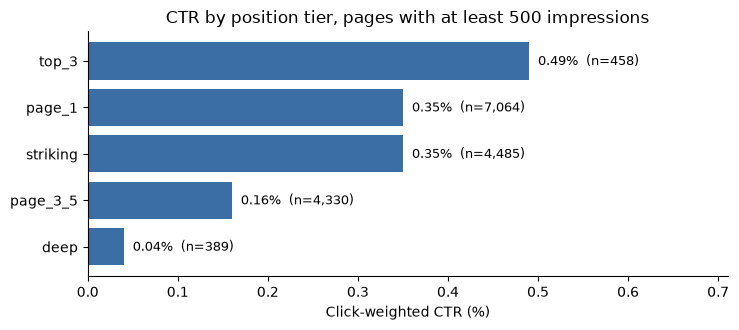

The raw top_3 mean is not a usable benchmark
all top_3 rows: 2,321, mean page CTR 1.48%, median impressions 3
avg_position = 0 rows inside top_3: 1,205, median impressions 1
top_3 rows with at least 500 impressions: 458, click-weighted CTR 0.49%

Below the tier benchmark is common, not rare
visible pages below their tier's click-weighted CTR: 11,538 (69.0%)
pages with a stored CTR of 0.00%: 13,212, median impressions 74, share of all impressions 3.3%


In [3]:
import matplotlib.pyplot as plt

FLOOR = 500
visible = df[df.impressions_90d >= FLOOR]

rows = []
for tier_name, frame in visible.groupby("position_tier"):
    rows.append({
        "position_tier": tier_name,
        "pages": len(frame),
        "median_impressions": int(frame.impressions_90d.median()),
        "observed_ctr_pct": round(frame.clicks_90d.sum() / frame.impressions_90d.sum() * 100, 2),
        "mean_page_ctr_pct": round(frame.ctr.mean(), 2),
        "zero_click_share_pct": round((frame.clicks_90d == 0).mean() * 100, 1),
    })

tier_table = (
    pd.DataFrame(rows)
    .set_index("position_tier")
    .sort_values("observed_ctr_pct", ascending=False)
)

print(f"Position tiers, pages with at least {FLOOR:,} impressions")
print(tier_table.to_string())

TIER_ORDER = ["top_3", "page_1", "striking", "page_3_5", "deep"]
plot_data = tier_table.loc[TIER_ORDER].iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 3.4))
bars = ax.barh(plot_data.index, plot_data["observed_ctr_pct"], color="#3b6ea5")

ax.set_xlabel("Click-weighted CTR (%)")
ax.set_title(f"CTR by position tier, pages with at least {FLOOR:,} impressions")
ax.set_xlim(0, plot_data["observed_ctr_pct"].max() * 1.45)

for bar, (_, row) in zip(bars, plot_data.iterrows()):
    ax.text(
        bar.get_width() + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{row['observed_ctr_pct']:.2f}%  (n={int(row['pages']):,})",
        va="center",
        fontsize=9,
    )

ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

top3 = df[df.position_tier == "top_3"]
top3_visible = top3[top3.impressions_90d >= FLOOR]

print("The raw top_3 mean is not a usable benchmark")
print(f"all top_3 rows: {len(top3):,}, mean page CTR {top3.ctr.mean():.2f}%, median impressions {int(top3.impressions_90d.median()):,}")
print(f"avg_position = 0 rows inside top_3: {(top3.avg_position == 0).sum():,}, median impressions {int(top3[top3.avg_position == 0].impressions_90d.median()):,}")
print(f"top_3 rows with at least {FLOOR:,} impressions: {len(top3_visible):,}, click-weighted CTR {top3_visible.clicks_90d.sum() / top3_visible.impressions_90d.sum() * 100:.2f}%")

benchmark = (
    visible.groupby("position_tier")
    .apply(lambda frame: frame.clicks_90d.sum() / frame.impressions_90d.sum() * 100, include_groups=False)
)
below = visible[visible.ctr < visible.position_tier.map(benchmark)]

print("\nBelow the tier benchmark is common, not rare")
print(f"visible pages below their tier's click-weighted CTR: {len(below):,} ({len(below) / len(visible):.1%})")
print(f"pages with a stored CTR of 0.00%: {(df.ctr == 0).sum():,}, median impressions {int(df[df.ctr == 0].impressions_90d.median()):,}, share of all impressions {df[df.ctr == 0].impressions_90d.sum() / df.impressions_90d.sum():.1%}")


## 4. Careful words: what I can and can't claim

**What the work will be able to say.**

- Observed: in this 90-day slice, a page received a measured number of impressions and clicks, and its CTR sat a measured distance below the click-weighted benchmark for its tier and volume band.
- Directional: pages near the top of the queue are better candidates for review than the median page in their tier, if the gap survives a volume floor and a client-holdout check.
- Decision support: the queue orders limited editor time. It does not prove that any page is broken.

**What it will never say.**

- That a title rewrite will cause a CTR lift. That needs a controlled test or a careful before-and-after design, and the search result can change underneath it.
- That the model knows what Google rewards. CTR is an outcome of rank, query mix, searchers, and the result page. It is not a direct grade of content quality.
- That a low CTR means the title is bad. Intent mismatch, branded queries, SERP features, and AI answers can all suppress clicks.
- That results from 32 clients and 30,000 pages generalize to the warehouse. I will re-check the frame on the larger release before the capstone.

**The metric, named before modeling.** Precision@20 on a client-holdout, reported next to the base rate and the tier-adjusted baseline. For the first check, a true positive is a page that an editor judges worth changing when the score and reason codes are hidden. For the later test, it is a page that stays below its tier benchmark in a later window once the warehouse daily table is in scope. The first check uses the hidden-score review because the starter slice has no daily history. The stronger test comes later. With 20 pages, one review moves precision by 5 percentage points, so I will report the count as well as the percentage.

**Why the holdout is by client.** Pages from one site share templates, audiences, and measurement quirks. A random row split would put sibling pages from the same client on both sides of the line and flatter the score. Holding out clients asks a harder and more useful question: does the pattern travel to a site the score has never seen?


In [4]:
CORE = [
    "content_id",
    "client_id",
    "position_tier",
    "impressions_90d",
    "clicks_90d",
    "ctr",
    "avg_position",
    "content_type",
    "main_intent",
    "word_count",
    "days_since_last_update",
    "sessions_90d",
    "engagement_rate",
    "trend_pct",
]

ROLE = {
    "content_id": "key, not a feature",
    "client_id": "group key for validation, not a feature",
    "position_tier": "benchmark segment",
    "impressions_90d": "feature and volume floor",
    "clicks_90d": "outcome input, excluded from learned features",
    "ctr": "outcome and benchmark, excluded from learned features",
    "avg_position": "feature, 0 recoded to missing",
    "content_type": "feature",
    "main_intent": "feature, missing as unknown",
    "word_count": "feature, missing by content type",
    "days_since_last_update": "feature",
    "sessions_90d": "context feature",
    "engagement_rate": "context feature, post-click",
    "trend_pct": "excluded, derived movement signal",
}

contract = pd.DataFrame({
    "dtype": df[CORE].dtypes.astype(str),
    "missing": df[CORE].isna().sum(),
    "role": pd.Series(ROLE),
})
print(contract.to_string())

recomputed_ctr = df.clicks_90d / df.impressions_90d * 100
max_rounding_gap = (recomputed_ctr - df.ctr).abs().max()

assert df.impressions_90d.min() >= 1, "impressions must be positive"
assert max_rounding_gap < 0.01, "ctr should equal clicks / impressions * 100"

print(f"\nCTR identity holds within {max_rounding_gap:.4f} pp, which is rounding.")
print(f"zero-click pages: {(df.clicks_90d == 0).mean():.1%}. A rate alone cannot separate 'no chance' from 'bad snippet'.")
print(f"avg_position = 0: {(df.avg_position == 0).sum():,} rows. Recode to missing before modeling; never read it as rank zero.")

excluded = ["clicks_90d", "ctr", "trend_pct", "trend_direction"]
print("\nExcluded from any learned feature set:", ", ".join(excluded))
print("Clicks and CTR are the outcome. The trend columns are a separate derived signal; I will not mix them into a CTR score.")


                          dtype  missing                                                   role
content_id                  str        0                                     key, not a feature
client_id                   str        0                group key for validation, not a feature
position_tier               str        0                                      benchmark segment
impressions_90d           int64        0                               feature and volume floor
clicks_90d                int64        0          outcome input, excluded from learned features
ctr                     float64        0  outcome and benchmark, excluded from learned features
avg_position            float64        0                          feature, 0 recoded to missing
content_type                str        0                                                feature
main_intent                 str     2374                            feature, missing as unknown
word_count              float64     7699

## Self-check

Before I submit, I confirm each line honestly:

- [x] Every section above is filled: markdown thinking and the code that backs it
- [x] The notebook runs top to bottom with no errors
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/`, then submit the repo URL on the card

The lane is provisional. I will confirm or change it by the end of Week 4, after the data contract and the first signal audit.
